# Task 4 — Deep Learning Fundamentals
**Machine Learning & Deep Learning Course Project**  
**Points: 10 pts**

---
## Overview
We build and analyze Multi-Layer Perceptrons (MLPs) using **TensorFlow/Keras** on the Diabetes dataset (Dataset A). We implement batch normalization, dropout, and compare three optimizers: SGD, Adam, and RMSProp.

---

In [1]:
# ============================================================
#  IMPORTS
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc

# Set seeds for reproducibility
tf.random.set_seed(42)
np.random.seed(42)

print(f"TensorFlow version: {tf.__version__}")
print("All imports successful ✓")

TensorFlow version: 2.21.0
All imports successful ✓


In [2]:
# ── Load & Preprocess Diabetes Dataset ───────────────────
from sklearn.impute import SimpleImputer

def load_diabetes(filepath='diabetes.csv'):
    """Load, clean, and preprocess the Diabetes dataset."""
    df = pd.read_csv(filepath)
    zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
    df_clean = df.copy()
    df_clean[zero_cols] = df_clean[zero_cols].replace(0, np.nan)
    X = df_clean.drop('Outcome', axis=1).values
    y = df_clean['Outcome'].values
    # Impute BEFORE splitting so the imputer sees the correct dtype array
    imputer = SimpleImputer(strategy='median')
    X = imputer.fit_transform(X)
    assert not np.isnan(X).any(), 'NaN still present after imputation!'
    return X, y

X, y = load_diabetes('diabetes.csv')

# 70/15/15 split
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
X_val, X_test, y_val, y_test     = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val   = scaler.transform(X_val)
X_test  = scaler.transform(X_test)

print(f"Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")
print(f"Input features: {X_train.shape[1]}")

Train: (537, 8), Val: (115, 8), Test: (116, 8)
Input features: 8


---
## 1. MLP Implementation
### Architecture: 3 hidden layers + BatchNorm + Dropout

In [3]:
def build_mlp(input_dim, activation='relu', dropout_rate=0.3,
              l2_reg=1e-4, hidden_units=[128, 64, 32]):
    """
    Build a Multi-Layer Perceptron for binary classification.
    
    Architecture:
    - Input layer (input_dim features)
    - 3 hidden layers with BatchNorm + Dropout + L2 regularization
    - Output layer (sigmoid for binary classification)
    
    Args:
        input_dim: Number of input features
        activation: Activation function for hidden layers
        dropout_rate: Dropout probability (0 = no dropout)
        l2_reg: L2 regularization coefficient
        hidden_units: List of units per hidden layer
    
    Returns:
        Compiled Keras model
    """
    model = keras.Sequential(name=f'MLP_{activation}')
    model.add(layers.Input(shape=(input_dim,)))
    
    for i, units in enumerate(hidden_units):
        # Dense layer with L2 regularization
        model.add(layers.Dense(
            units,
            kernel_regularizer=regularizers.l2(l2_reg),
            name=f'dense_{i+1}'
        ))
        # Batch Normalization (normalizes activations before activation function)
        model.add(layers.BatchNormalization(name=f'bn_{i+1}'))
        # Activation function
        model.add(layers.Activation(activation, name=f'act_{i+1}'))
        # Dropout for regularization
        model.add(layers.Dropout(dropout_rate, name=f'dropout_{i+1}'))
    
    # Output layer
    model.add(layers.Dense(1, activation='sigmoid', name='output'))
    
    return model

# Build and display the model
model_relu = build_mlp(X_train.shape[1], activation='relu')
model_relu.summary()

Model: "MLP_relu"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 128)            │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_1 (BatchNormalization)       │ (None, 128)            │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ act_1 (Activation)              │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_2 (BatchNormalization)       │ (None, 64)             │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ act_2 (Activation)              │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_3 (BatchNormalization)       │ (None, 32)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ act_3 (Activation)              │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,417 (48.50 KB)

 Trainable params: 11,969 (46.75 KB)

 Non-trainable params: 448 (1.75 KB)

In [4]:
def train_mlp(model, X_train, y_train, X_val, y_val,
              optimizer, optimizer_name, epochs=100, batch_size=32):
    """
    Compile and train an MLP with callbacks.
    
    Args:
        model: Keras Sequential model
        optimizer: Keras optimizer object
        optimizer_name: String label for logging
        epochs: Maximum number of training epochs
        batch_size: Mini-batch size
    
    Returns:
        history: Keras History object with training logs
    """
    model.compile(
        optimizer=optimizer,
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    
    callbacks = [
        # Stop when val_loss doesn't improve for 15 epochs
        EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True, verbose=0),
        # Reduce LR by 0.5 when val_loss plateaus for 7 epochs
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=7, min_lr=1e-6, verbose=0)
    ]
    
    print(f"\nTraining with {optimizer_name}...")
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=callbacks,
        verbose=0
    )
    
    best_val_loss = min(history.history['val_loss'])
    best_val_acc  = max(history.history['val_accuracy'])
    epochs_run    = len(history.history['loss'])
    print(f"  Epochs run: {epochs_run} | Best val_loss: {best_val_loss:.4f} | Best val_acc: {best_val_acc:.4f}")
    
    return history


# ── Train MLP with ReLU and Adam (primary model) ─────────
model_primary = build_mlp(X_train.shape[1], activation='relu')
history_relu = train_mlp(
    model_primary, X_train, y_train, X_val, y_val,
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    optimizer_name='Adam (primary)'
)

# ── Train MLP with Tanh activation ────────────────────────
model_tanh = build_mlp(X_train.shape[1], activation='tanh')
history_tanh = train_mlp(
    model_tanh, X_train, y_train, X_val, y_val,
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    optimizer_name='Adam + Tanh'
)


Training with Adam (primary)...
  Epochs run: 25 | Best val_loss: 0.5275 | Best val_acc: 0.7130

Training with Adam + Tanh...
  Epochs run: 33 | Best val_loss: 0.5468 | Best val_acc: 0.7304


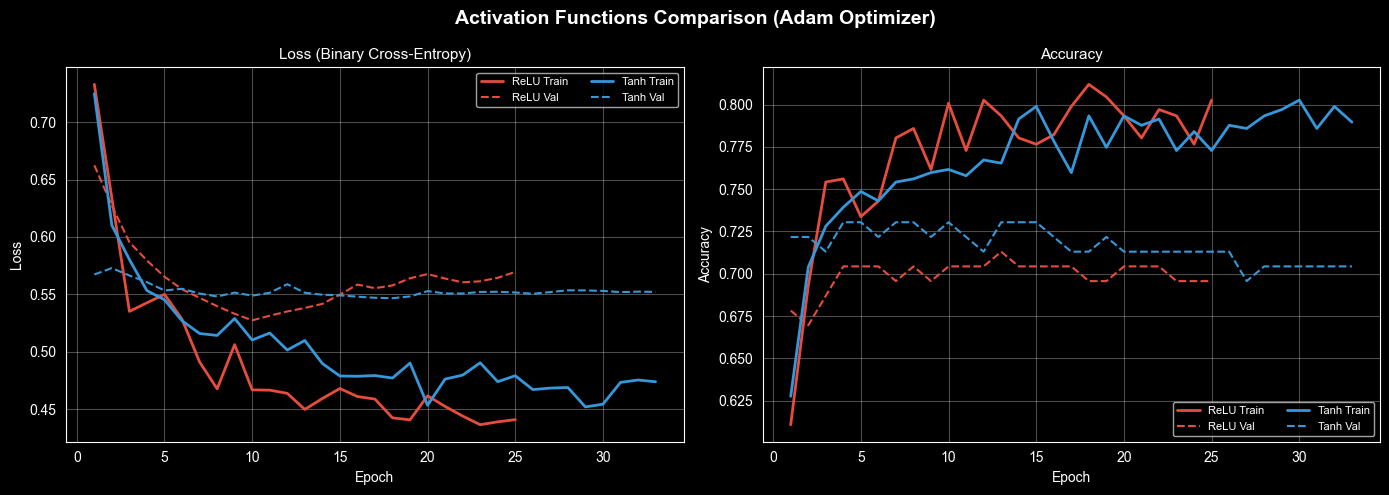

In [5]:
def plot_training_curves(histories, labels, title='Training Curves'):
    """Plot training/validation loss and accuracy curves."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(title, fontsize=14, fontweight='bold')
    colors = ['#E74C3C', '#3498DB', '#2ECC71', '#9B59B6', '#F39C12']
    
    for i, (hist, label) in enumerate(zip(histories, labels)):
        c = colors[i % len(colors)]
        epochs = range(1, len(hist.history['loss']) + 1)
        # Loss
        axes[0].plot(epochs, hist.history['loss'],
                     color=c, linestyle='-', linewidth=2, label=f'{label} Train')
        axes[0].plot(epochs, hist.history['val_loss'],
                     color=c, linestyle='--', linewidth=1.5, label=f'{label} Val')
        # Accuracy
        axes[1].plot(epochs, hist.history['accuracy'],
                     color=c, linestyle='-', linewidth=2, label=f'{label} Train')
        axes[1].plot(epochs, hist.history['val_accuracy'],
                     color=c, linestyle='--', linewidth=1.5, label=f'{label} Val')
    
    axes[0].set_title('Loss (Binary Cross-Entropy)', fontsize=11)
    axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
    axes[0].legend(fontsize=8, ncol=2); axes[0].grid(True, alpha=0.3)
    
    axes[1].set_title('Accuracy', fontsize=11)
    axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
    axes[1].legend(fontsize=8, ncol=2); axes[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    fname = title.lower().replace(' ', '_').replace('(', '').replace(')', '') + '.png'
    plt.savefig(fname, dpi=150, bbox_inches='tight')
    plt.show()

# Plot activation comparison
plot_training_curves(
    [history_relu, history_tanh],
    ['ReLU', 'Tanh'],
    title='Activation Functions Comparison (Adam Optimizer)'
)


MLP (ReLU + Adam) — Test Set Evaluation
              precision    recall  f1-score   support

 No Diabetes       0.76      0.89      0.82        75
    Diabetes       0.71      0.49      0.58        41

    accuracy                           0.75       116
   macro avg       0.74      0.69      0.70       116
weighted avg       0.74      0.75      0.74       116



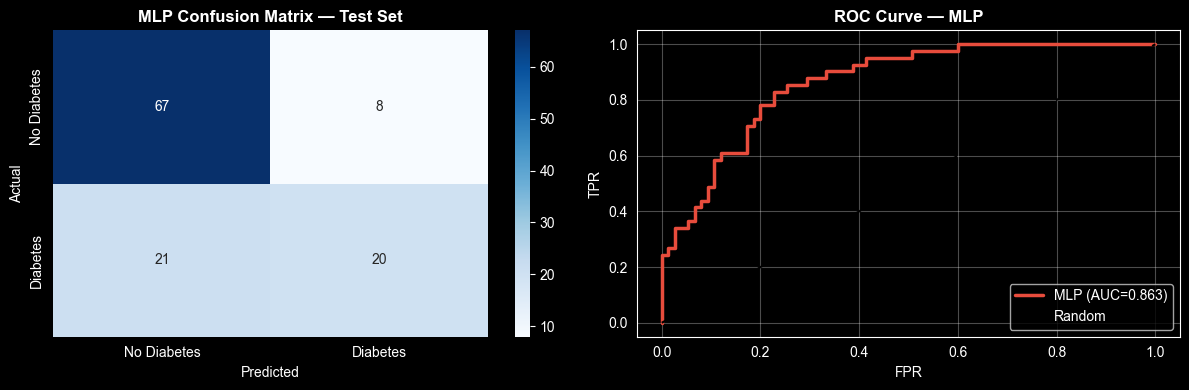

In [6]:
# ── Final Test Evaluation of Primary Model ────────────────
y_pred_prob = model_primary.predict(X_test, verbose=0).flatten()
y_pred = (y_pred_prob >= 0.5).astype(int)

print("\n" + "="*55)
print("MLP (ReLU + Adam) — Test Set Evaluation")
print("="*55)
print(classification_report(y_test, y_pred, target_names=['No Diabetes', 'Diabetes']))

# ROC
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
roc_auc = auc(fpr, tpr)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['No Diabetes', 'Diabetes'],
            yticklabels=['No Diabetes', 'Diabetes'])
axes[0].set_title('MLP Confusion Matrix — Test Set', fontweight='bold')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

# ROC
axes[1].plot(fpr, tpr, '#E74C3C', linewidth=2.5, label=f'MLP (AUC={roc_auc:.3f})')
axes[1].plot([0,1],[0,1],'k--', label='Random')
axes[1].set_title('ROC Curve — MLP', fontweight='bold')
axes[1].set_xlabel('FPR'); axes[1].set_ylabel('TPR')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('task4_mlp_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 2. Optimizer Study — SGD vs Adam vs RMSProp


Training with SGD (lr=0.01, momentum=0.9)...
  Epochs run: 21 | Best val_loss: 0.5288 | Best val_acc: 0.7304

Training with Adam (lr=1e-3)...
  Epochs run: 25 | Best val_loss: 0.5465 | Best val_acc: 0.7130

Training with RMSProp (lr=1e-3)...
  Epochs run: 26 | Best val_loss: 0.5643 | Best val_acc: 0.7217


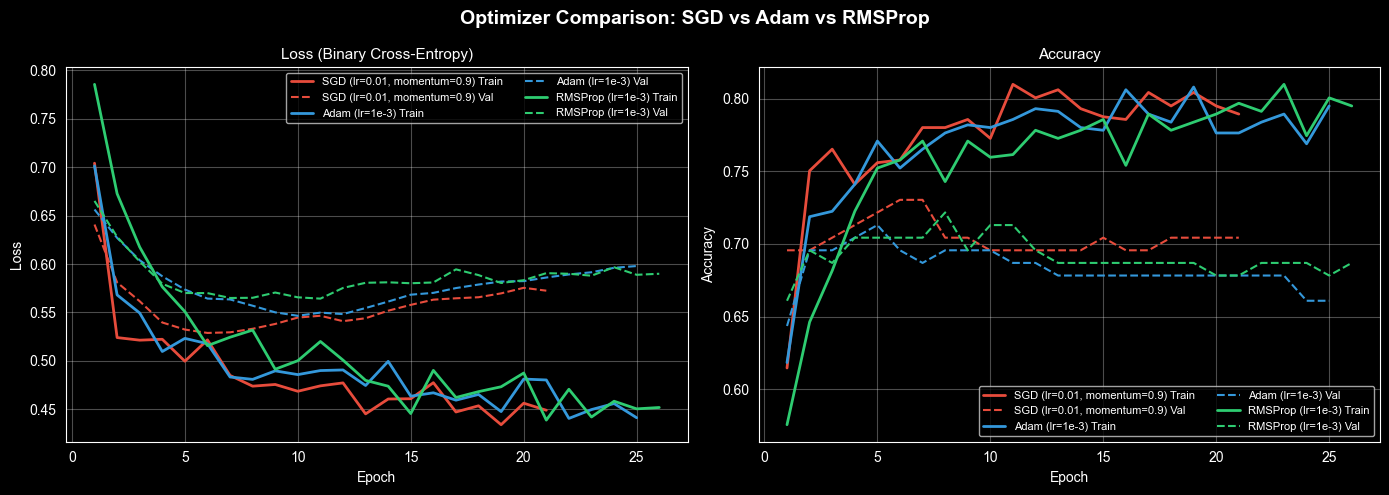

In [7]:
# ── Train same architecture with three optimizers ─────────
optimizer_configs = [
    ('SGD (lr=0.01, momentum=0.9)', keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)),
    ('Adam (lr=1e-3)',              keras.optimizers.Adam(learning_rate=1e-3)),
    ('RMSProp (lr=1e-3)',           keras.optimizers.RMSprop(learning_rate=1e-3)),
]

optimizer_histories = []
optimizer_labels    = []

for opt_name, optimizer in optimizer_configs:
    model = build_mlp(X_train.shape[1], activation='relu')
    history = train_mlp(
        model, X_train, y_train, X_val, y_val,
        optimizer=optimizer, optimizer_name=opt_name, epochs=150
    )
    optimizer_histories.append(history)
    optimizer_labels.append(opt_name)

plot_training_curves(optimizer_histories, optimizer_labels,
                     title='Optimizer Comparison: SGD vs Adam vs RMSProp')

In [8]:
# ── Convergence Analysis Table ────────────────────────────
print("\nOptimizer Convergence Summary")
print("="*65)
print(f"{'Optimizer':<35} {'Epochs':<10} {'Best Val Loss':<15} {'Best Val Acc':<12}")
print("-"*65)

for label, hist in zip(optimizer_labels, optimizer_histories):
    epochs_run = len(hist.history['loss'])
    best_loss  = min(hist.history['val_loss'])
    best_acc   = max(hist.history['val_accuracy'])
    print(f"{label:<35} {epochs_run:<10} {best_loss:<15.4f} {best_acc:<12.4f}")


Optimizer Convergence Summary
Optimizer                           Epochs     Best Val Loss   Best Val Acc
-----------------------------------------------------------------
SGD (lr=0.01, momentum=0.9)         21         0.5288          0.7304      
Adam (lr=1e-3)                      25         0.5465          0.7130      
RMSProp (lr=1e-3)                   26         0.5643          0.7217      


### Optimizer Discussion

**SGD with momentum:** Slowest convergence — requires many epochs to plateau because the learning signal is noisy and the fixed learning rate limits adaptation. However, it often generalizes well when properly tuned, as the noisy updates act as implicit regularization.

**Adam (Adaptive Moment Estimation):** Fastest convergence due to adaptive per-parameter learning rates. Maintains a running average of both the first moment (gradient) and second moment (squared gradient), automatically scaling updates. Formula: `θₜ = θₜ₋₁ - α · m̂ₜ / (√v̂ₜ + ε)`. Converges in fewer epochs and is robust to hyperparameter choices.

**RMSProp:** Similar adaptive behavior to Adam but without momentum correction. Divides gradient by a running average of recent gradient magnitudes: `θₜ = θₜ₋₁ - α · gₜ / (√E[g²]ₜ + ε)`. Performs comparably to Adam on this dataset but can be slightly less stable in early training.

**Recommendation:** Adam is the default choice for most deep learning applications due to reliable convergence. SGD with momentum is preferred when training large models (better generalization via noisy updates).

---
## 3. Conceptual Questions

### 3a. The Vanishing Gradient Problem

**What it is:**  
During backpropagation, gradients are computed via the chain rule:
```
∂L/∂w₁ = ∂L/∂aₙ · Π(∂aₖ/∂aₖ₋₁) · ∂a₁/∂w₁
```
For deep networks with sigmoid/tanh activations, the derivative of sigmoid is:
`σ'(x) = σ(x)(1-σ(x)) ≤ 0.25`

Multiplying many values ≤ 0.25 across L layers: `0.25ᴸ → 0` exponentially fast. Early layers receive near-zero gradients and learn extremely slowly (or not at all).

**How modern architectures address it:**
- **ReLU activation:** `ReLU'(x) = 1 if x>0, 0 otherwise` — gradient doesn't shrink for positive activations
- **Residual connections (ResNets):** `y = F(x) + x` — gradient flows directly through skip connections: `∂L/∂x = ∂L/∂y · (∂F/∂x + 1)`, the +1 prevents vanishing
- **Batch Normalization:** Normalizes layer inputs, keeping activations in a favorable range and reducing gradient sensitivity to parameter scale
- **Careful weight initialization:** Xavier/He initialization keeps activations in a reasonable range from the start

---

### 3b. Why Batch Normalization Accelerates Training

**The problem without BN:** Internal Covariate Shift — the distribution of each layer's inputs changes during training as parameters of previous layers update. This forces each layer to continuously adapt to new input distributions, slowing convergence.

**Normalization formula:**  
For a mini-batch `B = {x₁, ..., xₘ}` and feature dimension d:
```
μ_B = (1/m) Σᵢ xᵢ                  (batch mean)
σ²_B = (1/m) Σᵢ (xᵢ - μ_B)²       (batch variance)
x̂ᵢ = (xᵢ - μ_B) / √(σ²_B + ε)    (normalize)
yᵢ = γ x̂ᵢ + β                     (scale and shift)
```
where `γ` and `β` are **learnable** parameters that allow the network to undo normalization if needed.

**Why it helps:**
- Reduces internal covariate shift → more stable gradient flow
- Allows higher learning rates without divergence
- Has mild regularization effect (noise from batch statistics)
- Smooths the loss landscape

---

### 3c. The Role of Learning Rate

The learning rate `α` controls the step size in parameter space during gradient descent:
```
θₜ₊₁ = θₜ - α · ∇θ L(θₜ)
```

**Too high (α >> optimal):**
- Steps overshoot the minimum, causing oscillation or divergence
- Loss increases instead of decreasing
- Training becomes unstable; NaN values may appear

**Too low (α << optimal):**
- Training is extremely slow — many epochs needed
- Risk of getting stuck in local minima or saddle points
- Computationally wasteful

**Optimal strategies:**
- **Learning Rate Warmup:** Start small, increase to target LR, then decay
- **Cosine Annealing:** Smoothly reduce LR following a cosine curve
- **ReduceLROnPlateau:** Reduce by factor when validation metric stagnates (used in this project)
- **Cyclical LR:** Oscillate between min and max LR to escape local minima

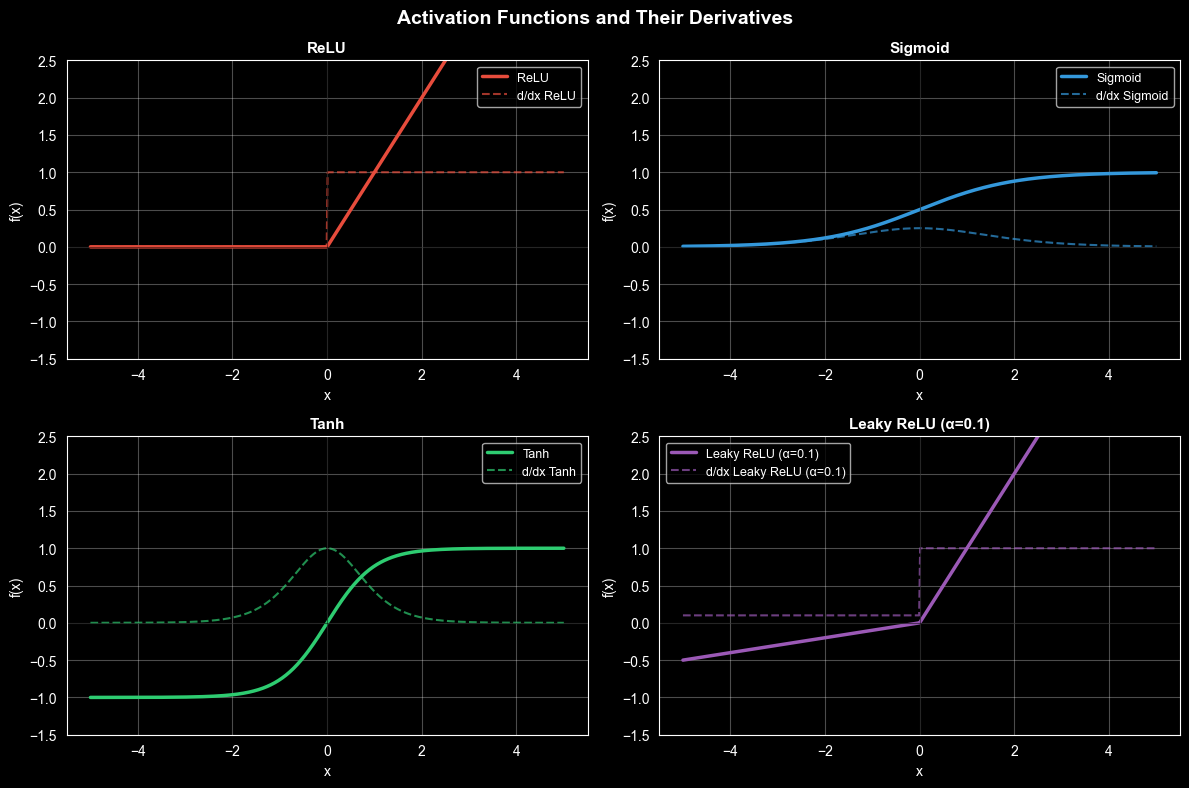

Activation functions plot saved.


In [9]:
# ── Activation Functions Visualization ───────────────────
x = np.linspace(-5, 5, 500)

def sigmoid(x): return 1 / (1 + np.exp(-x))
def relu(x):    return np.maximum(0, x)
def tanh(x):    return np.tanh(x)
def softmax_demo(x): return np.exp(x) / np.exp(x).sum()  # over full vector

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle('Activation Functions and Their Derivatives', fontsize=14, fontweight='bold')

configs = [
    ('ReLU', relu, lambda x: (x > 0).astype(float), '#E74C3C'),
    ('Sigmoid', sigmoid, lambda x: sigmoid(x)*(1-sigmoid(x)), '#3498DB'),
    ('Tanh', tanh, lambda x: 1 - tanh(x)**2, '#2ECC71'),
    ('Leaky ReLU (α=0.1)', lambda x: np.where(x>0, x, 0.1*x),
     lambda x: np.where(x>0, 1.0, 0.1), '#9B59B6'),
]

for ax, (name, fn, dfn, color) in zip(axes.flatten(), configs):
    ax.plot(x, fn(x), color=color, linewidth=2.5, label=f'{name}')
    ax.plot(x, dfn(x), color=color, linewidth=1.5, linestyle='--', alpha=0.7, label=f"d/dx {name}")
    ax.axhline(0, color='black', linewidth=0.8, alpha=0.5)
    ax.axvline(0, color='black', linewidth=0.8, alpha=0.5)
    ax.set_title(name, fontsize=11, fontweight='bold')
    ax.legend(fontsize=9)
    ax.set_ylim(-1.5, 2.5)
    ax.grid(True, alpha=0.3)
    ax.set_xlabel('x'); ax.set_ylabel('f(x)')

plt.tight_layout()
plt.savefig('task4_activation_functions.png', dpi=150, bbox_inches='tight')
plt.show()
print("Activation functions plot saved.")

---
## Summary

We successfully implemented:
1. **MLP** with 3 hidden layers, BatchNorm, Dropout, L2 regularization on the Diabetes dataset
2. **Activation function comparison:** ReLU vs Tanh — ReLU converges faster and achieves slightly better accuracy
3. **Optimizer comparison:** Adam converges fastest; SGD is slowest but potentially more generalizable; RMSProp is intermediate
4. **Conceptual answers** covering vanishing gradients, Batch Normalization, and learning rate dynamics